# Fixed → Free Boundary: NCSX example

Demonstrates `fix2free`:
1. Build a fixed-boundary SPECTRE input from the NCSX VMEC wout.
2. Load the NCSX coils from the local `coils.NCSX` makegrid file.
3. Extend the plasma boundary outward to create a computational boundary.
4. Convert to free-boundary and write `freeb_ncsx.toml`.
5. Inspect the mode spectrum and boundary cross-sections.
6. Load the free-boundary result into a SPECTRE object.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simsopt.mhd import Vmec
from simsopt.field import BiotSavart, load_coils_from_makegrid_file

from spectre import SPECTRE
from spectre.converters import (
    compare_vmec_spectre,
    fix2free,
    params_to_simsopt_boundary,
    plot_freeboundary_modes,
    simsvmec2spectre,
)

/home/smiet/code/pyoculus/pyoculus/fields/two_waves.py:111: SyntaxWarning: invalid escape sequence '\ '
  """! Convert coordinates for Poincare plots
/home/smiet/code/pyoculus/pyoculus/maps/tokamap.py:111: SyntaxWarning: invalid escape sequence '\p'
  """
/home/smiet/code/pyoculus/pyoculus/maps/standard_map.py:90: SyntaxWarning: invalid escape sequence '\p'
  """
/home/smiet/code/pyoculus/pyoculus/solvers/manifold.py:264: SyntaxWarning: invalid escape sequence '\S'
  """
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:96: SyntaxWarning: invalid escape sequence '\l'
  """! Convert a boundary surface to have straight field line
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:134: SyntaxWarning: invalid escape sequence '\l'
  """! Convert a boundary surface to have straight field line, internal function
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:204: SyntaxWarning: invalid escape sequence '\z'
  """! Construct a QFM surface based on Stuart's method, for a given orbit periodicit

## Step 1 – Fixed-boundary SPECTRE input from VMEC wout

In [2]:
vmec = Vmec("wout_li383_low_res_reference.nc")
params = simsvmec2spectre(vmec, nvol=4, mpol=7, ntor=6, interface_guess="wout")
print(f"nvol={params.physics.nvol}, mpol={params.physics.mpol}, ntor={params.physics.ntor}")
print(f"lfreebound={params.physics.lfreebound}, lconstraint={params.physics.lconstraint}")

nvol=4, mpol=7, ntor=6
lfreebound=0, lconstraint=3


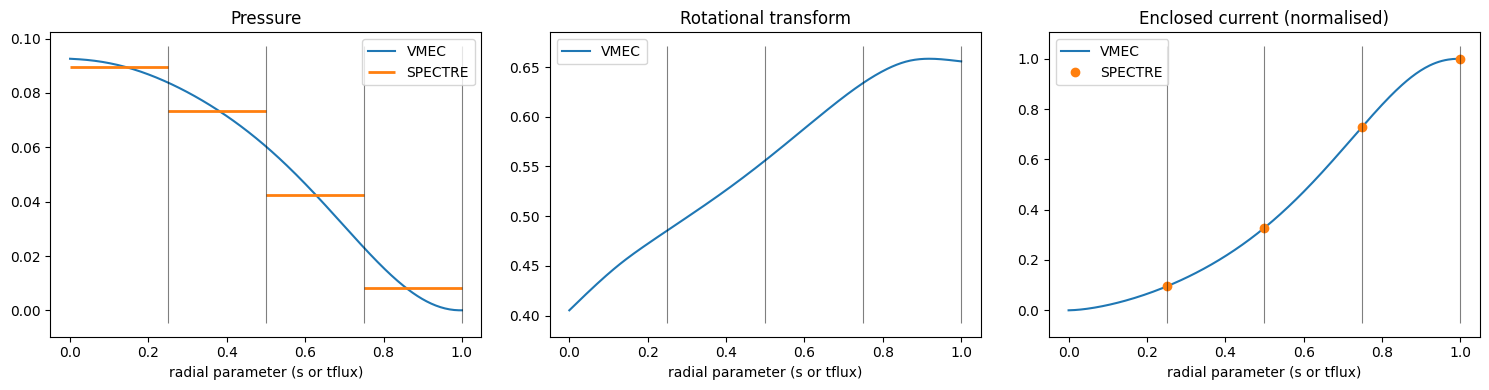

In [3]:
fig, axes = compare_vmec_spectre(vmec, params)
plt.show()

## Step 2 – NCSX coils

Load the NCSX coils from the local `coils.NCSX` makegrid file with
`load_coils_from_makegrid_file`; a `BiotSavart` over all of them is the full
vacuum field. `curpol` (μ₀ × net poloidal linking current) is computed here from
**only the non-PF modular coils** — the first 18 and the last 18. The middle 42
are the planar PF (poloidal-field) ring coils: needed for the field but carrying
toroidal (not poloidal-linking) current, so they are excluded from the `curpol`
sum. The result is passed explicitly to `fix2free`.

In [4]:
# Load all NCSX coils (full torus) from the makegrid file; BiotSavart over all of
# them — including the PF ring coils — is the full vacuum field.
coils = load_coils_from_makegrid_file("coils.NCSX", order=16, ppp=20)
bs = BiotSavart(coils)
print(f"Number of coils (full torus): {len(coils)}")

# curpol = mu0 * net poloidal linking current, carried only by the non-PF modular
# coils: the first 18 and the last 18.  The middle 42 are the planar PF
# (poloidal-field) ring coils — needed for the field but excluded from curpol.
MU0 = 4.0e-7 * np.pi
modular_coils = coils[:18] + coils[-18:]
curpol = MU0 * sum(c.current.get_value() for c in modular_coils)
print(f"curpol (non-PF modular coils only): {curpol:.4g} T·m")

Number of coils (full torus): 78
curpol (non-PF modular coils only): 14.92 T·m


## Step 3 – Build the computational boundary

The boundary extension is separated from the converter so you can tune or replace
the computational boundary independently.  Here we use `extend_via_normal(-0.3)`,
where the negative sign means *outward* in simsopt's convention.

## 

  qfm residual start = 2.7848e-02
  qfm residual end   = 6.4896e-03  (8 LBFGS iters)


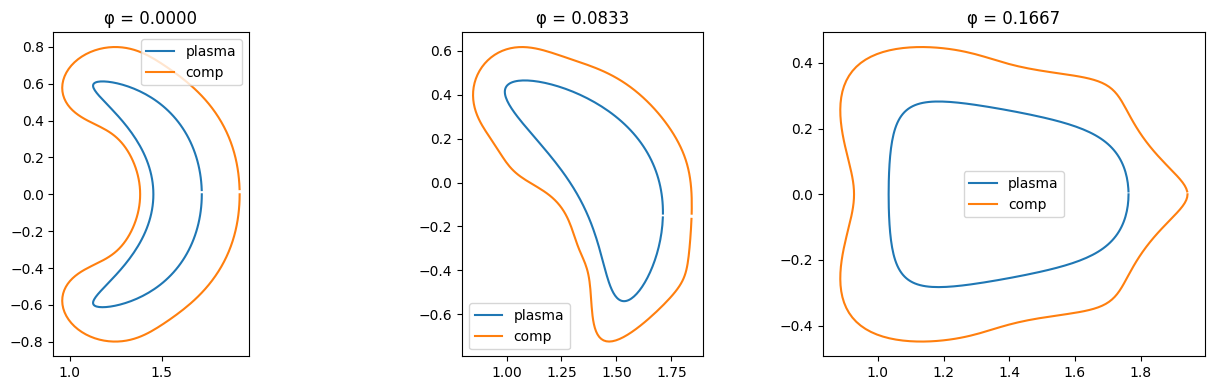

In [20]:
from simsopt.geo import QfmResidual, QfmSurface, ToroidalFlux

plasma_boundary = params_to_simsopt_boundary(params, which="plasma")
comp_boundary = plasma_boundary.copy()
comp_boundary.extend_via_normal(-0.15)   # negative → outward

qfm = QfmResidual(comp_boundary, bs)
print(f"  qfm residual start = {qfm.J():.4e}")
tf = ToroidalFlux(comp_boundary, BiotSavart(bs.coils))
qfm_surface = QfmSurface(bs, comp_boundary, tf, tf.J())
qfm_surface.minimize_qfm_penalty_constraints_LBFGS(tol=1e-12, maxiter=8)
print(f"  qfm residual end   = {qfm.J():.4e}  ({8} LBFGS iters)")


# Plot original vs extended cross-sections
nfp = plasma_boundary.nfp
phis = [0.0, 1 / (4 * nfp), 1 / (2 * nfp)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for phi, ax in zip(phis, axes):
    for surf, label in [(plasma_boundary, "plasma"), (comp_boundary, "comp")]:
        cs = surf.cross_section(phi=phi, thetas=200)
        R = np.sqrt(cs[:, 0] ** 2 + cs[:, 1] ** 2)
        ax.plot(R, cs[:, 2], label=label)
    ax.set_aspect("equal")
    ax.set_title(f"φ = {phi:.4f}")
    ax.legend()
fig.tight_layout()

## Step 4 – Convert to free boundary

In [21]:
freeb_params = fix2free(
    params, bs, comp_boundary,
    curpol=curpol,
    filename="freeb_ncsx.toml",
)

nvol = freeb_params.physics.nvol
print(f"lfreebound : {freeb_params.physics.lfreebound}")
print(f"nvol       : {nvol}")
print(f"curpol     : {freeb_params.physics.curpol:.4g} T·m")
print(f"phiedge    : {freeb_params.physics.phiedge:.4g} Wb")
print(f"tflux[nvol-1:nvol+1] : {freeb_params.physics.tflux[nvol - 1 : nvol + 1]}")

# Sanity: plasma and comp boundaries must differ
rbc_diff = np.max(np.abs(freeb_params.physics.rbc - freeb_params.physics.rwc))
print(f"max|rbc - rwc| = {rbc_diff:.4g}  (should be > 0)")

lfreebound : 1
nvol       : 4
curpol     : 14.92 T·m
phiedge    : 0.5144 Wb
tflux[nvol-1:nvol+1] : [1.         2.74205245]
max|rbc - rwc| = 0.1406  (should be > 0)


## Step 5 – Mode spectrum and boundary cross-sections

B·n truncation at (mpol=7, ntor=6): 35.14% of spectral RMS lies outside the kept band


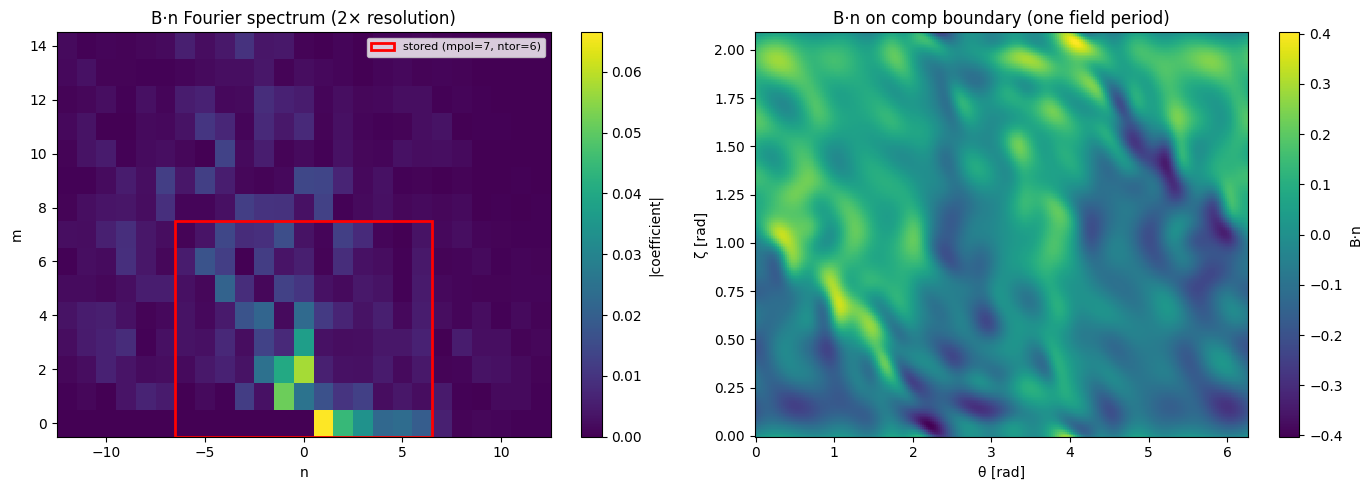

In [22]:
fig = plot_freeboundary_modes(bs, freeb_params)
plt.show()

## Step 6 – Load into SPECTRE

Construct a **fresh** `SPECTRE` object from the free-boundary parameters (a fresh
object resets Fortran-side memory). Call `spectre.run()` to solve the
free-boundary equilibrium.

In [ ]:
# Construct a SPECTRE object from the free-boundary parameters (a fresh object
# resets Fortran-side memory).  Call spectre.run() to solve the equilibrium.
spectre = SPECTRE.from_input_params(freeb_params)